# Science case: exoplanet atmospheres at high resolution with CSHELL

CSHELL at R = 43,000 (100 um slit) or R = 18,000 (bare fiber) covers 1.08-1.75 um, but its free
spectral range is only ~2.5e-3 lambda: **one setting is ~27 A wide at 1.08 um and ~40 A at 1.55 um**.
That rules out broad-band cross-correlation over hundreds of lines in one shot, and points to
**single strong features**. The best one is the metastable **He I 1083.3 nm triplet**, the
workhorse of escaping-atmosphere studies (Spake et al. 2018; Allart et al. 2018), where transit
depths of 0.5-5% over a ~1 A core are common for hot Jupiters and warm Neptunes.

**Assumptions used here** (knobs):

* He 10830 setting: 1081-1086 nm, R = 43,000 (3 resels across the ~0.7 A FWHM core) and R = 18,000.
* Detection metric: the excess absorption averaged over `n_core` resels in the planet line, measured
  in-transit minus out-of-transit, with equal in/out exposure. Precision per transit:
  $\sigma = \sqrt{2}/(\mathrm{SNR}_{resel}\sqrt{n_{core}\,N_{exp,in}})$.
* Individual exposures of 300 s; the exposure is split into reads only if the brightest pixel would
  saturate (`full_well` from the preset, placeholder 80 ke$^-$).
* Transit duration 2 h (so 24 in-transit exposures) and the same out of transit.
* Slit throughput for R = 43,000 is a placeholder (0.5) until measured.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
EXP = 300.0
N_IN = int(2*3600/EXP)      # in-transit exposures per transit
def he_setup(name, n_tel=20):
    return LFASTETC(name, n_telescopes=n_tel, wavelength_min_nm=1081, wavelength_max_nm=1086)

def precision_per_transit(etc, src, n_core, exp=EXP, n_in=N_IN):
    r = etc.snr(src, exp)
    if r.saturated.any():                         # split the exposure to stay below full well
        n_exp = int(np.ceil(r.peak_e_per_pixel.max() / (0.8*etc.instrument.full_well)))
        r = etc.snr(src, exp, n_exp=n_exp)
    snr = r.at(1083.3)["snr"]
    return np.sqrt(2) / (snr*np.sqrt(n_core*n_in)), snr, r.n_exp

targets = {  # (Teff, J mag, He depth): representative well-known He 10830 detections
    "HD 189733 b": (5000, 5.6, 0.010),
    "WASP-69 b":   (4700, 8.0, 0.035),
    "HAT-P-11 b":  (4800, 7.6, 0.012),
    "GJ 3470 b":   (3650, 8.8, 0.015),
    "WASP-107 b":  (4400, 9.4, 0.055),
}

## Per-transit precision and detection significance

In [3]:
for mode, n_core in (("cshell_r43000", 3), ("cshell_r18000", 2)):
    etc = he_setup(mode)
    print(f"--- {etc.instrument.description} ---")
    for name, (teff, jmag, depth) in targets.items():
        sig, snr, n_exp = precision_per_transit(etc, Source.blackbody(teff, jmag, "J"), n_core)
        print(f"{name:12s} J={jmag:4.1f}: SNR/resel/300s={snr:6.1f} (reads={n_exp})  "
              f"sigma={100*sig:.3f}% per transit  ->  {depth/sig:5.1f} sigma on a {100*depth:.1f}% line")

--- CSHELL, 100 um slit, R=43,000, 1.08-1.75 um (slit loss placeholder) ---
HD 189733 b  J= 5.6: SNR/resel/300s= 237.1 (reads=1)  sigma=0.070% per transit  ->   14.2 sigma on a 1.0% line
WASP-69 b    J= 8.0: SNR/resel/300s=  70.5 (reads=1)  sigma=0.236% per transit  ->   14.8 sigma on a 3.5% line
HAT-P-11 b   J= 7.6: SNR/resel/300s=  87.8 (reads=1)  sigma=0.190% per transit  ->    6.3 sigma on a 1.2% line
GJ 3470 b    J= 8.8: SNR/resel/300s=  41.9 (reads=1)  sigma=0.397% per transit  ->    3.8 sigma on a 1.5% line
WASP-107 b   J= 9.4: SNR/resel/300s=  29.5 (reads=1)  sigma=0.565% per transit  ->    9.7 sigma on a 5.5% line
--- CSHELL, native fiber resolution R=18,000, 1.08-1.75 um ---
HD 189733 b  J= 5.6: SNR/resel/300s= 522.7 (reads=2)  sigma=0.039% per transit  ->   25.6 sigma on a 1.0% line
WASP-69 b    J= 8.0: SNR/resel/300s= 168.2 (reads=1)  sigma=0.121% per transit  ->   28.8 sigma on a 3.5% line
HAT-P-11 b   J= 7.6: SNR/resel/300s= 204.4 (reads=1)  sigma=0.100% per transit  ->  

## Detection significance versus host J magnitude

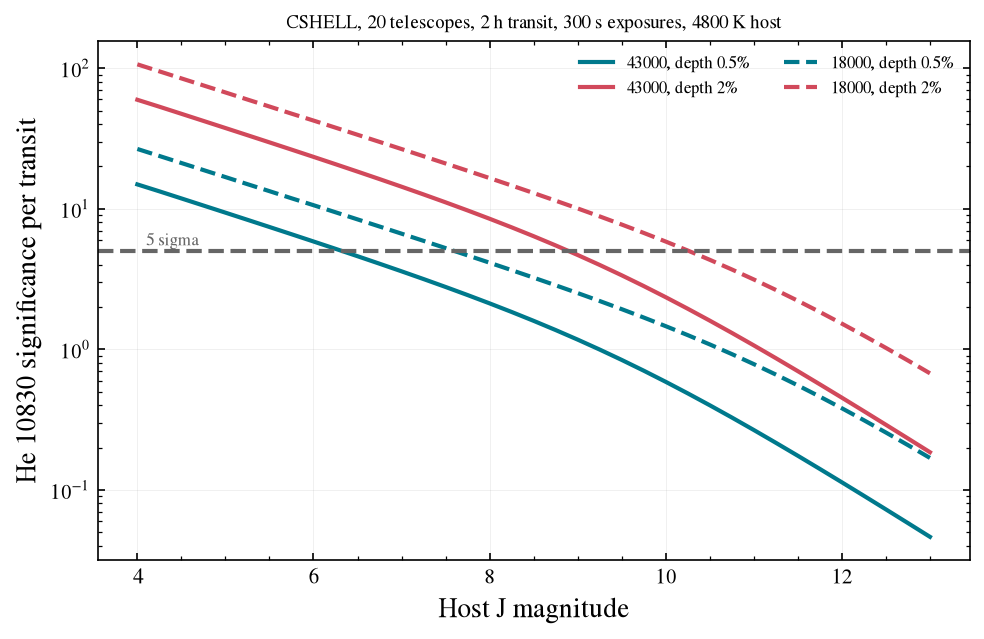

In [4]:
jmags = np.linspace(4, 13, 37)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for mode, n_core, ls in (("cshell_r43000", 3, '-'), ("cshell_r18000", 2, '--')):
    etc = he_setup(mode)
    for depth, color in ((0.005, 'C0'), (0.02, 'C1')):
        sig = np.array([precision_per_transit(etc, Source.blackbody(4800, j, "J"), n_core)[0] for j in jmags])
        ax.plot(jmags, depth/sig, ls=ls, color=color, label=f"{etc.instrument.resolving_power:.0f}, depth {100*depth:g}%")
ax.axhline(5, color='0.4', ls='--'); ax.text(4.1, 5.5, "5 sigma", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_xlabel("Host J magnitude"); ax.set_ylabel("He 10830 significance per transit")
ax.legend(fontsize=8, ncol=2); ax.set_title("CSHELL, 20 telescopes, 2 h transit, 300 s exposures, 4800 K host", fontsize=9);

## Number of transits for a 5-sigma detection of a 1% line

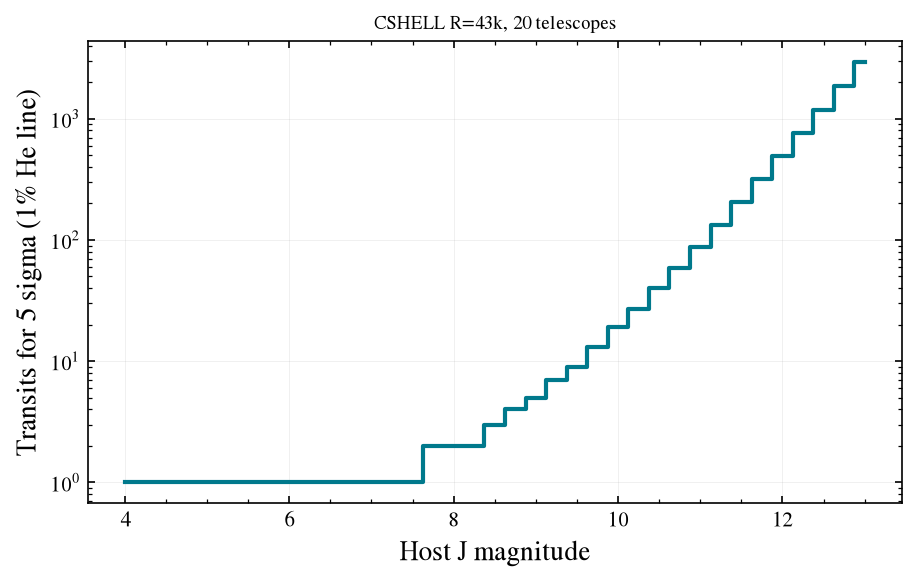

In [5]:
etc = he_setup("cshell_r43000")
sig = np.array([precision_per_transit(etc, Source.blackbody(4800, j, "J"), 3)[0] for j in jmags])
n_transits = np.ceil((5*sig/0.01)**2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(jmags, n_transits, where='mid')
ax.set_yscale('log'); ax.set_xlabel("Host J magnitude"); ax.set_ylabel("Transits for 5 sigma (1% He line)")
ax.set_title("CSHELL R=43k, 20 telescopes", fontsize=9);

## Why read noise and the array size matter here

CSHELL's 22 e$^-$ read noise and 0.5 e$^-$/s dark current are large. With all fibers combined the
detector terms are paid once; with independent spectra they are paid $N$ times.

In [6]:
ns = [5, 10, 20, 40, 80]
src = Source.blackbody(4800, 9.0, "J")
for combine in ("fiber", "independent"):
    row = []
    for n in ns:
        etc = LFASTETC("cshell_r43000", telescope=Telescope(n, "18um", combine=combine), wavelength_min_nm=1081, wavelength_max_nm=1086)
        row.append(f"N={n}: {100*precision_per_transit(etc, src, 3)[0]:.2f}%")
    print(f"{combine:12s} " + "  ".join(row))

fiber        N=5: 1.25%  N=10: 0.71%  N=20: 0.43%  N=40: 0.27%  N=80: 0.18%
independent  N=5: 2.47%  N=10: 1.75%  N=20: 1.23%  N=40: 0.87%  N=80: 0.62%


## Cross-correlation within one echelle setting (order-of-magnitude)

For completeness: a CCF over $N_{lines}$ planetary lines of individual contrast $\epsilon$
(relative to the star) in one 40 A window at 1.55 um gives per transit
$S/N_{CCF} \approx \epsilon\, \mathrm{SNR}_{resel} \sqrt{N_{lines} N_{exp}}$.
With only ~10-30 usable water/CO lines in 40 A, the He line is the better bet, as the numbers show.

In [7]:
etc = LFASTETC("cshell_r43000", n_telescopes=20, wavelength_min_nm=1550, wavelength_max_nm=1554)
for name, (teff, jmag, _) in list(targets.items())[:3]:
    hmag = Source.blackbody(teff, jmag, "J").magnitude("H")
    r = etc.snr(Source.blackbody(teff, hmag, "H"), EXP)
    snr = float(np.median(r.snr))
    for n_lines in (10, 30):
        print(f"{name:12s} H={hmag:4.1f}: SNR/resel={snr:5.0f}; CCF S/N per transit (eps=5e-4, {n_lines} lines) = {5e-4*snr*np.sqrt(n_lines*N_IN):.1f}")

HD 189733 b  H= 5.3: SNR/resel=  199; CCF S/N per transit (eps=5e-4, 10 lines) = 1.5
HD 189733 b  H= 5.3: SNR/resel=  199; CCF S/N per transit (eps=5e-4, 30 lines) = 2.7
WASP-69 b    H= 7.7: SNR/resel=   59; CCF S/N per transit (eps=5e-4, 10 lines) = 0.5
WASP-69 b    H= 7.7: SNR/resel=   59; CCF S/N per transit (eps=5e-4, 30 lines) = 0.8
HAT-P-11 b   H= 7.3: SNR/resel=   73; CCF S/N per transit (eps=5e-4, 10 lines) = 0.6
HAT-P-11 b   H= 7.3: SNR/resel=   73; CCF S/N per transit (eps=5e-4, 30 lines) = 1.0
